In [2]:
import torch
import torchao
from torchao.quantization import quantize_, int4_weight_only
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import tensorflow as tf
import numpy as np
import os
import time
import pandas as pd
import psutil
import tracemalloc
import ai_edge_torch  # The requested tool
from ai_edge_torch.generative.quantize import quant_recipes, quant_attrs
from torchvision.models import resnet18
from tqdm import tqdm
import copy
import subprocess
import matplotlib.pyplot as plt
import seaborn as sns


device = 'cpu' #'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

STAGE 2:
• Convert the best compressed model and distilled model from Stage 1 to TensorFlow Lite format.
• Test INT8 and INT4 quantization on the converted models.
• Simulate edge inference: measure latency on a CPU-only environment for all tested models.
• Calculate memory footprint and energy estimates.
• Deliverables: .tflite model files, performance benchmarks (latency, size, accuracy)
• Tools: TensorFlow Lite • PyTorch • ONNX




In [5]:

#BASELINE
baseline_model = resnet18(num_classes=10)
baseline_model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False) # inspired by the github example: this is to avoid downsampling the already small images from CIFAR10 too quickly
baseline_model.maxpool = nn.Identity() 

#MAIN
class BiggerStudent(nn.Module):
    def __init__(self):
        super(BiggerStudent, self).__init__()
        
        # 3 to 32 
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1, bias=False), # Double conv
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2) 
        )
        
        # 32 to 64
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2) # 16x16 -> 8x8
        )
        
        # 64 to 128
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2) # 8x8 -> 4x4
        )
        
        # Global average pooling: averaging 4x4 spatial dimensions to 1x1
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(128, 10)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        
        x = self.gap(x)       
        x = x.flatten(1)      
        x = self.fc(x)
        return x
    

trained_student_big = BiggerStudent()
trained_student_big.load_state_dict(torch.load('big_student_distilled_best.pth', weights_only=True))
trained_student_big.eval()

trained_baseline = baseline_model
#trained_baseline.load_state_dict(torch.load('resnet18_best.pth', weights_only=True))
trained_baseline.load_state_dict(torch.load('resnet18_best.pth', map_location='cpu'))

trained_student_big.to(device)
trained_baseline.to(device)



ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): Identity()
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), p

In [6]:

### DATA LOADING ###
batch_size=1 # batch size 1 to simulate edge latency

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

testSet = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)
testLoader = torch.utils.data.DataLoader(testSet, batch_size=batch_size, shuffle=False, num_workers=2)
    


/home/cavey/feddf_stage2/.venv/lib/python3.12/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [7]:
#HELPERS

###this is just to keep the helpers in one place, I'll define them as I go

# representative data for int8 quantization (for calibration)
def representative_data_gen():
    for i, (images, _) in enumerate(testLoader):
        if i > 100: break # 100 imgs for calibration
        # PyTorch is NCHW (1, 3, 32, 32)
        # Permute to NHWC (1, 32, 32, 3) for TensorFlow
        img_np = images.permute(0, 2, 3, 1).numpy()
        yield [img_np]

In [10]:
#TFLite conversion w/ ai edge torch (NOW IT'S CALLED LiteRT Torch ALL OF THIS WAS WRITTEN THAT WAS THE CASE!!!!)
def convert_to_tflite(pytorch_model, model_name, quantization="float32"):
    model_copy = copy.deepcopy(pytorch_model).cpu().eval()
    tflite_path = f"{model_name}_{quantization}.tflite"
    sample_input = (torch.randn(1, 3, 32, 32),)
    
    print(f"[{model_name}] Processing ({quantization})...")
    
    try:
        if quantization == "float32":
            edge_model = ai_edge_torch.convert(model_copy, sample_input)
            edge_model.export(tflite_path)
            
        elif quantization == "int8":
            # Dynamic INT8 (The best you can do for CNN on CPU)
            config = quant_recipes.full_dynamic_recipe()
            edge_model = ai_edge_torch.convert(model_copy, sample_input, quant_config=config)
            edge_model.export(tflite_path)
            
        elif quantization == "fp16":
            # 2x compression, which, you know, isn't int4, but I'm not having ANOTHER sleepless night trying to add int4. This is insane, nothing seems to support int4 for convolutional networks. I tried to get advice from a couple other students and that didn't save me either. I guess I'm just doing fp16 now, which is, obviously, defeat, but I'll have to take that.
            # TLDR int4 on tflite doesn't seem to be possible for CNNs
            # I was going to imitate it originally but I wanted actual quantization to happen
            config = quant_recipes.full_fp16_recipe()
            edge_model = ai_edge_torch.convert(model_copy, sample_input, quant_config=config)
            edge_model.export(tflite_path)

        if os.path.exists(tflite_path):
            size_mb = os.path.getsize(tflite_path) / (1024**2)
            print(f"    Success: {tflite_path} ({size_mb:.2f} MB)")
            return tflite_path
            
    except Exception as e:
        print(f"    Error: {e}")
        return None

In [11]:
#benchmarker

def evaluate_tflite_model(tflite_model_path):
    if not tflite_model_path or not os.path.exists(tflite_model_path): return None
    
    interpreter = tf.lite.Interpreter(model_path=tflite_model_path)
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()
    
    # Auto-detect layout (NCHW vs NHWC)
    input_shape = input_details[0]['shape']
    input_dtype = input_details[0]['dtype']
    input_index = input_details[0]['index']
    
    latencies = []
    correct = 0
    total = 0
    limit = 200 
    
    tracemalloc.start()
    
    for i, (images, labels) in enumerate(tqdm(testLoader, total=limit, desc=f"Bench: {os.path.basename(tflite_model_path)}")):
        if i >= limit: break
        
        # Handle Layout
        if input_shape[1] == 3: img_np = images.numpy()
        else: img_np = images.permute(0, 2, 3, 1).numpy()
        
        # Handle Quantization
        if input_dtype == np.int8:
            scale, zero_point = input_details[0]['quantization']
            img_np = (img_np / scale + zero_point).astype(np.int8)
        else:
            img_np = img_np.astype(np.float32)

        interpreter.set_tensor(input_index, img_np)

        start = time.time()
        interpreter.invoke()
        end = time.time()
        latencies.append((end - start) * 1000)

        output = interpreter.get_tensor(output_details[0]['index'])
        if np.argmax(output) == labels.item(): correct += 1
        total += 1

    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    
    avg_latency = np.mean(latencies)
    size_mb = os.path.getsize(tflite_model_path) / (1024 * 1024)
    energy_mj = 4.0 * (avg_latency / 1000) * 1000 
    
    return {
        "Model": os.path.basename(tflite_model_path),
        "Size (MB)": round(size_mb, 2),
        "Accuracy (%)": round(100 * correct / total, 2),
        "Latency (ms)": round(avg_latency, 2),
        "Memory Peak (MB)": round(peak / 1024**2, 2),
        "Est. Energy (mJ)": round(energy_mj, 2)
    }

In [14]:
results = []

#1. Old baseline
print("\n--- Processing Baseline (Float32) ---")
if 'trained_baseline' in locals():
    trained_baseline.to('cpu')
    path = convert_to_tflite(trained_baseline, "Baseline", "float32")
    results.append(evaluate_tflite_model(path))
    
#2. BiggerStudent
print("\n--- Processing BiggerStudent ---")
if 'trained_student_big' in locals():
    trained_student_big.to('cpu')
    
    # a. FP32/UNCOMPRESSED
    path = convert_to_tflite(trained_student_big, "BiggerStudent", "float32")
    results.append(evaluate_tflite_model(path))
    
    # b. DYNAMIC INT8 (The "Best" Model)
    path = convert_to_tflite(trained_student_big, "BiggerStudent", "int8")
    results.append(evaluate_tflite_model(path))
    
    # c. FP16 (The "Alternative" Model)
    path = convert_to_tflite(trained_student_big, "BiggerStudent", "fp16")
    results.append(evaluate_tflite_model(path))

#3. INT8 PTQ resnet
print("\n--- Processing Baseline (INT8) ---")
if 'trained_baseline' in locals():
    trained_baseline.to('cpu')
    path = convert_to_tflite(trained_baseline, "Baseline", "int8")
    results.append(evaluate_tflite_model(path))

# Report
results = [r for r in results if r is not None]
df = pd.DataFrame(results)
print("\n=== Final Stage 2 Results ===")
print(df.to_string(index=False))
df.to_csv("stage2_final_benchmarks.csv", index=False)


--- Processing BiggerStudent ---
[BiggerStudent] Processing (float32)...
INFO:tensorflow:Assets written to: /tmp/tmplsglxq6p/assets


INFO:tensorflow:Assets written to: /tmp/tmplsglxq6p/assets
W0000 00:00:1768955876.586083     511 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1768955876.586124     511 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
2026-01-21 01:37:56.586256: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /tmp/tmplsglxq6p
2026-01-21 01:37:56.586719: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-01-21 01:37:56.586725: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmplsglxq6p
2026-01-21 01:37:56.590182: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-01-21 01:37:56.615466: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmplsglxq6p
2026-01-21 01:37:56.621931: I tensorflow/cc/saved_model/loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 35678 

    Success: BiggerStudent_float32.tflite (1.11 MB)


Bench: BiggerStudent_float32.tflite:   0%|                                                      | 0/200 [00:00<?, ?it/s]/usr/lib/python3.12/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
Bench: BiggerStudent_float32.tflite:  94%|████████████████████████████████████████▍  | 188/200 [00:00<00:00, 492.91it/s]/usr/lib/python3.12/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
Bench: BiggerStudent_float32.tflite: 100%|███████████████████████████████████████████| 200/200 [00:00<00:00, 450.15it/s]


[BiggerStudent] Processing (int8)...
INFO:tensorflow:Assets written to: /tmp/tmp7kjr4o8q/assets


...


--- Processing Baseline (INT8) ---
[Baseline] Processing (int8)...
INFO:tensorflow:Assets written to: /tmp/tmpkngqwobe/assets


INFO:tensorflow:Assets written to: /tmp/tmpkngqwobe/assets
W0000 00:00:1768955886.069012     511 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1768955886.069052     511 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
2026-01-21 01:38:06.069179: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /tmp/tmpkngqwobe
2026-01-21 01:38:06.070114: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-01-21 01:38:06.070122: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpkngqwobe
2026-01-21 01:38:06.079288: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-01-21 01:38:06.155309: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpkngqwobe
2026-01-21 01:38:06.171964: I tensorflow/cc/saved_model/loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 102787

    Success: Baseline_int8.tflite (10.74 MB)


Bench: Baseline_int8.tflite:   0%|                                                              | 0/200 [00:00<?, ?it/s]/usr/lib/python3.12/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
Bench: Baseline_int8.tflite:  86%|███████████████████████████████████████████▌       | 171/200 [00:00<00:00, 354.23it/s]/usr/lib/python3.12/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
Bench: Baseline_int8.tflite: 100%|███████████████████████████████████████████████████| 200/200 [00:00<00:00, 332.81it/s]



=== Final Stage 2 Results ===
                       Model  Size (MB)  Accuracy (%)  Latency (ms)  Memory Peak (MB)  Est. Energy (mJ)
BiggerStudent_float32.tflite       1.11          88.5          0.33              0.14              1.32
   BiggerStudent_int8.tflite       0.29          88.5          0.11              0.13              0.43
   BiggerStudent_fp16.tflite       0.56          88.5          0.65              0.14              2.61
        Baseline_int8.tflite      10.74          88.0          1.07              0.13              4.26


In [12]:
results = []

tflite_models = [
    "Baseline_float32.tflite",
    "BiggerStudent_float32.tflite",
    "BiggerStudent_int8.tflite",
    "BiggerStudent_fp16.tflite",
    "Baseline_int8.tflite"
]


print("--- Evaluating Existing TFLite Models ---")

for model_path in tflite_models:
    if os.path.exists(model_path):
        metrics = evaluate_tflite_model(model_path)
        if metrics:
            results.append(metrics)
    else:
        print(f"Warning: {model_path} not found")

results = [r for r in results if r is not None]
df = pd.DataFrame(results)
print("\n=== Final Stage 2 Results ===")
print(df.to_string(index=False))
df.to_csv("stage2_final_benchmarks.csv", index=False)

/home/cavey/feddf_stage2/.venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


--- Evaluating Existing TFLite Models ---


Bench: Baseline_float32.tflite:   0%|                                                           | 0/200 [00:00<?, ?it/s]/usr/lib/python3.12/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
Bench: Baseline_float32.tflite:  93%|████████████████████████████████████████████▋   | 186/200 [00:01<00:00, 169.99it/s]/usr/lib/python3.12/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
Bench: Baseline_int8.tflite: 100%|███████████████████████████████████████████████████| 200/200 [00:00<00:00, 351.66it/s]


=== Final Stage 2 Results ===
                       Model  Size (MB)  Accuracy (%)  Latency (ms)  Memory Peak (MB)  Est. Energy (mJ)
     Baseline_float32.tflite      42.63          87.0          4.01              0.12             16.05
BiggerStudent_float32.tflite       1.11          88.5          0.26              0.11              1.05
   BiggerStudent_int8.tflite       0.29          88.5          0.10              0.11              0.41
   BiggerStudent_fp16.tflite       0.56          88.5          0.62              0.11              2.47
        Baseline_int8.tflite      10.74          88.0          1.02              0.11              4.10


<module 'matplotlib.pyplot' from '/home/cavey/feddf_stage2/.venv/lib/python3.12/site-packages/matplotlib/pyplot.py'>

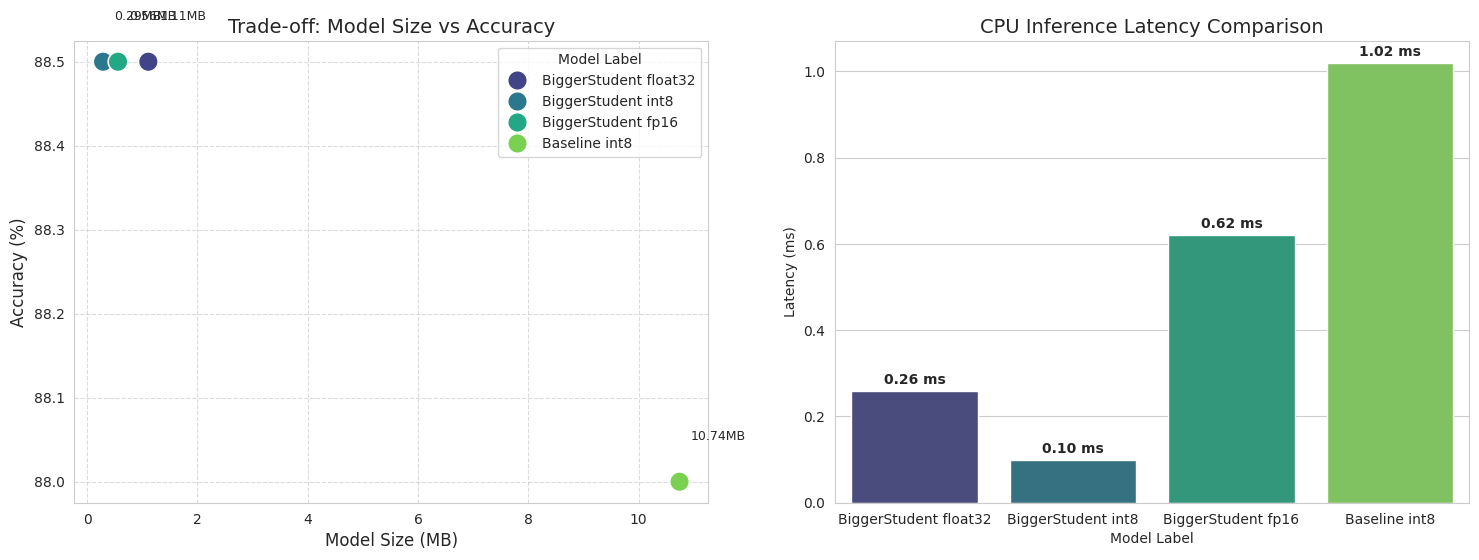

In [20]:


#I filter out the fp32 resnet as it's very clearly outperformed by everything else and will mess up the the visualizations too much
df_viz = df[~df['Model'].str.contains('Baseline_float32')].copy()

df_viz['Model Label'] = df_viz['Model'].str.replace('.tflite', '').str.replace('_', ' ')

plt.figure(figsize=(18, 6))
sns.set_style("whitegrid")

# plot 1: size v accuracy tradeoff
plt.subplot(1, 2, 1)
sns.scatterplot(
    data=df_viz, 
    x='Size (MB)', 
    y='Accuracy (%)', 
    hue='Model Label', 
    s=200,  # Marker size
    palette='viridis',
    legend='full'
)

for i, row in df_viz.iterrows():
    plt.text(
        row['Size (MB)'] + 0.2, 
        row['Accuracy (%)'] + 0.05, 
        f"{row['Size (MB)']}MB", 
        fontsize=9
    )

plt.title('Trade-off: Model Size vs Accuracy', fontsize=14)
plt.xlabel('Model Size (MB)', fontsize=12)
plt.ylabel('Accuracy (%)', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)

# plot 2: inference latency comparison
plt.subplot(1, 2, 2)
barplot = sns.barplot(
    data=df_viz, 
    x='Model Label', 
    y='Latency (ms)', 
    hue='Model Label', 
    palette='viridis',
    legend=False
)

for p in barplot.patches:
    barplot.annotate(
        f'{p.get_height():.2f} ms', 
        (p.get_x() + p.get_width() / 2., p.get_height()), 
        ha='center', va='center', 
        xytext=(0, 8), 
        textcoords='offset points',
        fontsize=10, fontweight='bold'
    )

plt.title('CPU Inference Latency Comparison', fontsize=14)
plt

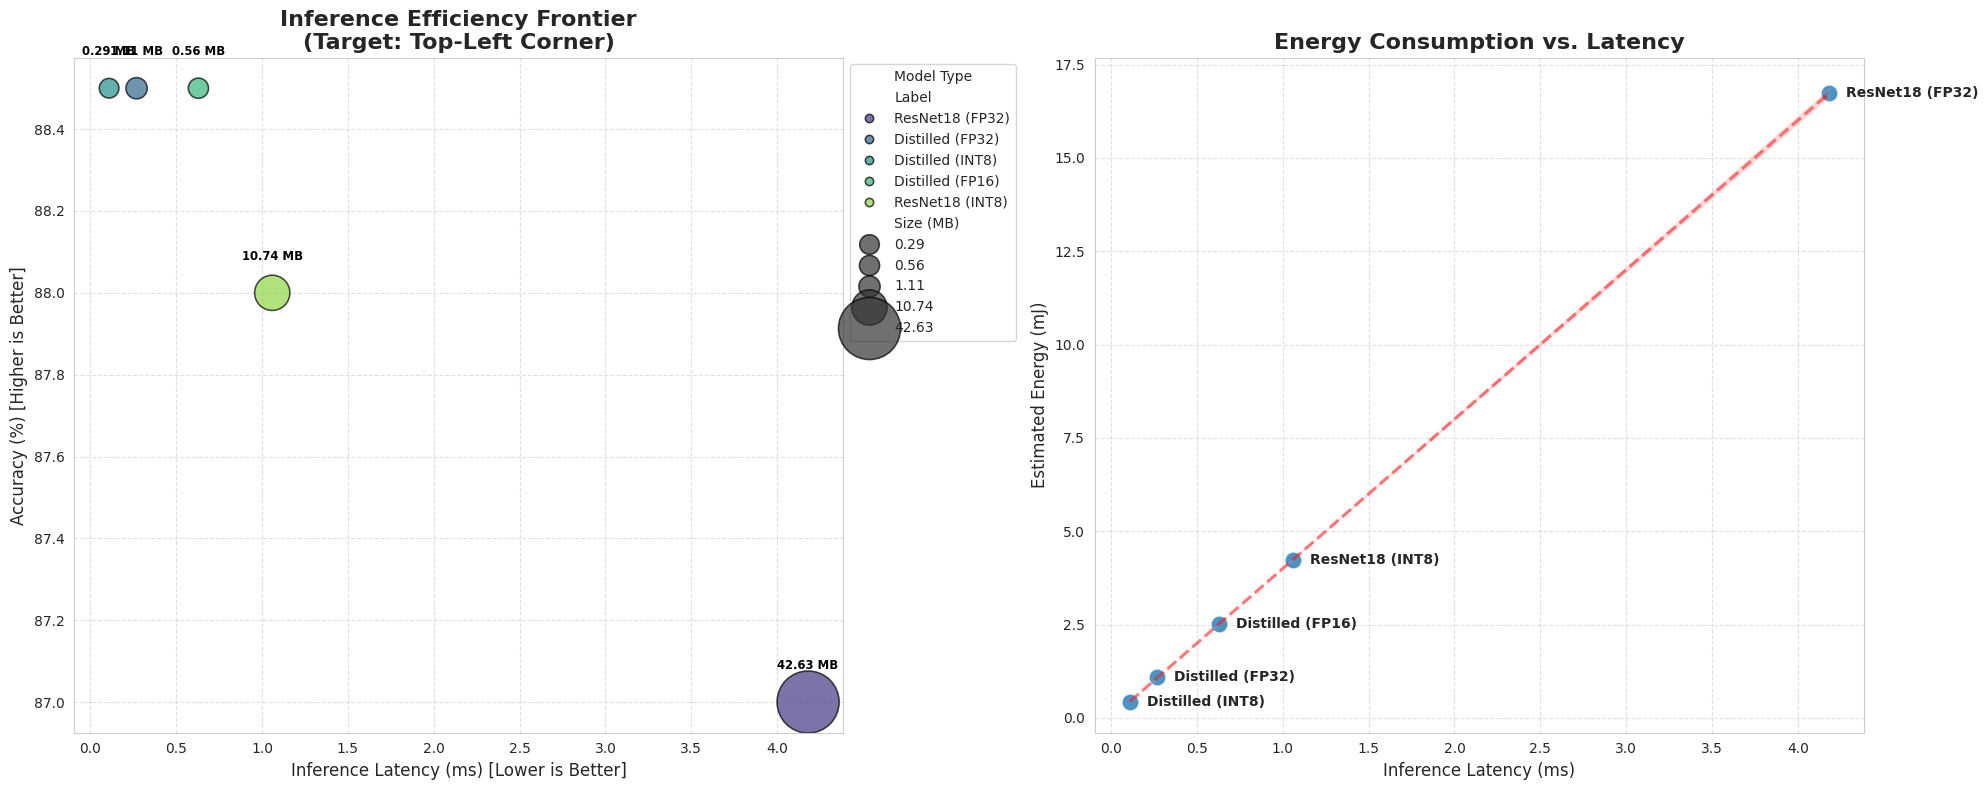

In [ ]:

if 'df' not in locals():
    if os.path.exists("stage2_final_benchmarks.csv"):
        print("Loading data from CSV...")
        df = pd.read_csv("stage2_final_benchmarks.csv")
    else:
        print("Dataframe not found. Reconstructing from report data...")
        # Hardcoded data from your Screenshot page 7/13
        data = {
            'Model': [
                'Baseline_float32.tflite', 
                'BiggerStudent_float32.tflite',
                'BiggerStudent_int8.tflite', 
                'BiggerStudent_fp16.tflite', 
                'Baseline_int8.tflite'
            ],
            'Size (MB)': [42.63, 1.11, 0.29, 0.56, 10.74],
            'Accuracy (%)': [87.0, 88.5, 88.5, 88.5, 88.0],
            'Latency (ms)': [4.18, 0.27, 0.11, 0.63, 1.06],
            'Est. Energy (mJ)': [16.73, 1.09, 0.43, 2.53, 4.23]
        }
        df = pd.DataFrame(data)

# --- 2. Pre-processing for clean labels ---
def clean_label(name):
    name = name.replace('.tflite', '')
    name = name.replace('Baseline', 'ResNet18')
    name = name.replace('BiggerStudent', 'Distilled')
    name = name.replace('_float32', ' (FP32)')
    name = name.replace('_int8', ' (INT8)')
    name = name.replace('_fp16', ' (FP16)')
    return name

df['Label'] = df['Model'].apply(clean_label)

# --- 3. Visualization ---
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

#Inference Efficiency Frontier plot
sns.scatterplot(
    data=df,
    x='Latency (ms)',
    y='Accuracy (%)',
    size='Size (MB)',
    hue='Label',
    sizes=(200, 2000),
    alpha=0.7,
    ax=axes[0],
    palette='viridis',
    edgecolor='black'
)

for i, row in df.iterrows():
    axes[0].text(
        row['Latency (ms)'], 
        row['Accuracy (%)'] + 0.08, 
        f"{row['Size (MB)']} MB", 
        horizontalalignment='center',
        size='small',
        weight='bold',
        color='black'
    )

axes[0].set_title('Inference Efficiency Frontier\n(Target: Top-Left Corner)', fontsize=16, weight='bold')
axes[0].set_xlabel('Inference Latency (ms) [Lower is Better]', fontsize=12)
axes[0].set_ylabel('Accuracy (%) [Higher is Better]', fontsize=12)
axes[0].legend(bbox_to_anchor=(1, 1), loc='upper left', title="Model Type")
axes[0].grid(True, linestyle='--', alpha=0.6)

#energy vs latency regression plot
sns.regplot(
    data=df,
    x='Latency (ms)',
    y='Est. Energy (mJ)',
    ax=axes[1],
    scatter_kws={'s': 150, 'edgecolor': 'white'},
    line_kws={'color': 'red', 'alpha': 0.5, 'linestyle': '--'},
    color='tab:blue'
)

for i, row in df.iterrows():
    axes[1].text(
        row['Latency (ms)'] + 0.1, 
        row['Est. Energy (mJ)'], 
        row['Label'], 
        horizontalalignment='left',
        verticalalignment='center',
        size='medium',
        weight='semibold'
    )

axes[1].set_title('Energy Consumption vs. Latency', fontsize=16, weight='bold')
axes[1].set_xlabel('Inference Latency (ms)', fontsize=12)
axes[1].set_ylabel('Estimated Energy (mJ)', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('stage2_advanced_visualizations.png')
plt.show()



!!!

P.S. The visualizations were created with the assistance of an LLM